# 04 · Regresión: prever la carga de trabajo del laboratorio

El cribado eligió un análisis de regresión, y aquí se modela a fondo en tres niveles: los modelos
del curso con su configuración de partida (pasada didáctica), un cribado de los factores de la
tubería con un arreglo ortogonal de Taguchi y el afinamiento de hiperparámetros de lo que sobrevive,
evaluado una sola vez en validación antes de congelar el modelo.

← Anterior: [03 · Cribado de análisis](03_cribado_analisis.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [05 · Clasificación y Bayes](05_clasificacion_bayes.ipynb) →

## Código del proyecto

La celda siguiente recrea el paquete `proyecto/` dentro de la sesión, de forma que el notebook funciona en Google Colab sin clonar ningún repositorio: basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo. La sección puede plegarse desde su título. Trae también los guiones de las etapas anteriores: si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (49 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 3 etapas previas (se reconstruyen si faltan);
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (63 archivos, 180 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="3b9a56b2782217c56effec12250b9aab8b3da68fa3f1e60b8f06c80b8b56527a",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import regresion

iniciar_etapa("04_regresion")
c = regresion.iniciar()
mostrar(c.encabezado)

## 1. El problema y las referencias ingenuas

Un error de pocas muestras solo significa algo al lado de lo que el laboratorio ya consigue sin
modelo. Las referencias ingenuas (repetir lo de ayer, promediar la última semana) se evalúan en los
mismos tramos de validación de los bloques temporales que usarán los modelos.

In [2]:
regresion.planteamiento(c).mostrar()

In [3]:
regresion.referencias(c).mostrar()

Referencia,Bloque 1,Bloque 2,Bloque 3,Bloque 4
base_dia_anterior,21.43,22.68,29.32,28.17
base_media_5,15.67,16.46,22.51,20.39
Dummy (media),15.49,15.54,24.90,21.69


## 2. Pasada didáctica: los modelos del curso

Cada modelo usa el grupo de variables ampliado y el preprocesamiento por defecto (imputación por la
mediana y estandarización), sin afinar.

### 2.1 Regresión lineal simple

La variable con mayor correlación absoluta con el objetivo, en unidades originales, para que la
pendiente se lea en muestras por día.

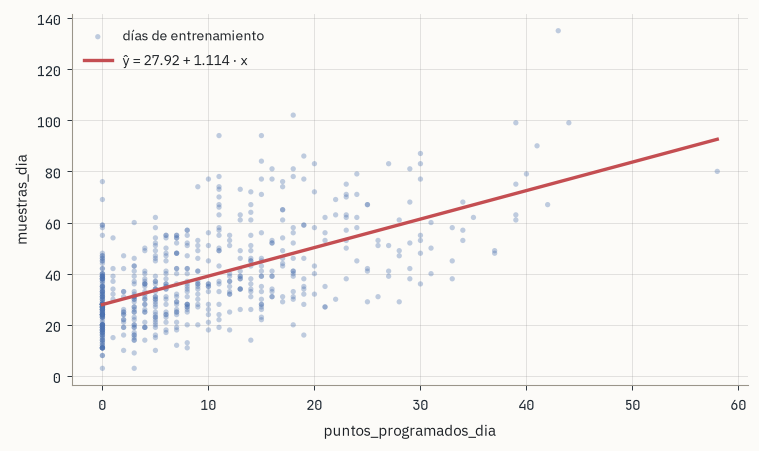

In [4]:
regresion.recta_simple(c).mostrar()

### 2.2 Árbol de regresión con poda por costo-complejidad

Se calcula la ruta de poda del árbol completo y se elige el `ccp_alpha` con menor RMSE medio en los
bloques: la complejidad la decide la validación, no una profundidad fijada a mano.

In [5]:
regresion.poda(c).mostrar()

ccp_alpha,Hojas,RMSE medio,Desv. RMSE
0.000,95,17.326,1.558
0.871,48,16.919,1.542
1.290,37,17.190,1.938
1.971,24,16.588,1.882
3.798,12,16.203,2.310
20.522,2,17.003,4.229


### 2.3 Regresión múltiple, KNN, árbol y perceptrón en los mismos bloques

Modelo,Tipo,MAE,RMSE,± RMSE,R²,± R²,Habilidad,Habilidad mínima
base_dia_anterior,referencia,20.165,25.399,3.926,-1.053,0.241,-0.357,-0.381
base_media_5,referencia,14.697,18.757,3.244,-0.111,0.078,0.000,0.000
Dummy (media),referencia,14.603,19.405,4.679,-0.167,0.120,-0.026,-0.106
Lineal simple (puntos_programados_dia),modelo,12.287,15.956,3.959,0.208,0.139,0.157,0.088
Lineal múltiple,modelo,10.446,13.310,2.262,0.440,0.047,0.290,0.283
KNN,modelo,11.498,15.416,3.409,0.259,0.067,0.183,0.140
Árbol podado,modelo,12.694,16.203,2.310,0.151,0.190,0.131,0.040
Perceptrón multicapa,modelo,10.900,14.308,2.807,0.350,0.131,0.238,0.171


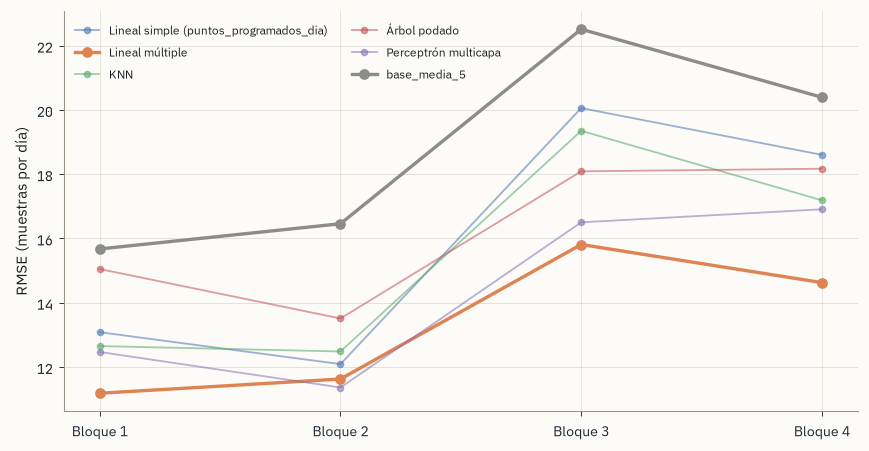

In [6]:
regresion.didactica(c).mostrar()

### 2.4 Qué dicen los coeficientes de la regresión múltiple

Con las variables estandarizadas, cada coeficiente es el cambio esperado en la carga cuando la
variable sube una desviación estándar y las demás quedan fijas.

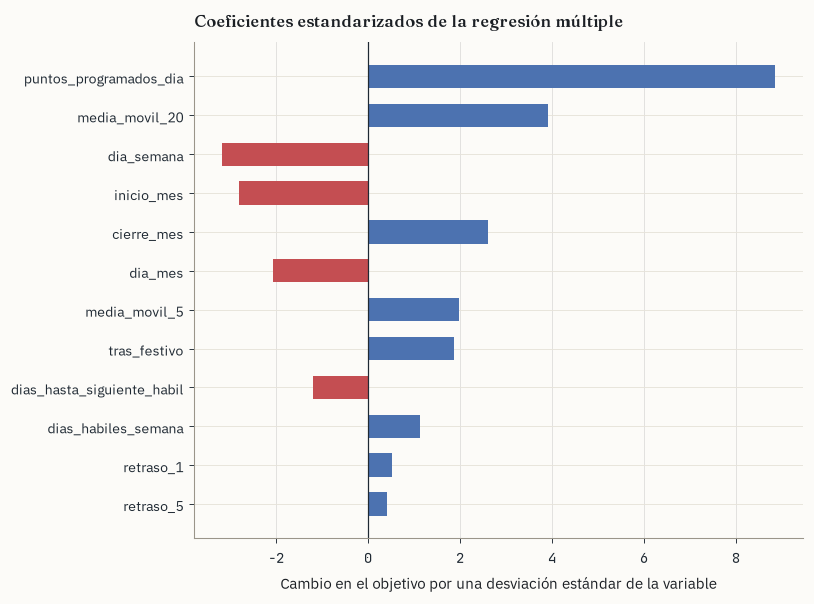

In [7]:
regresion.coeficientes(c).mostrar()

## 3. Nivel 2: cribado de la tubería con un arreglo L16 de Taguchi

Además del modelo, la tubería decide el escalado, el grupo de variables, si el objetivo va en
logaritmo, si se seleccionan variables y cómo se codifican las discretas. Probar todo exige
4 × 2⁵ = 128 corridas; un arreglo ortogonal L16 estima los efectos principales de los seis factores
con 16, porque cada nivel aparece el mismo número de veces frente a los niveles de los demás. El
precio es que algunas interacciones quedan confundidas con efectos principales: la tabla de
confusiones dice exactamente cuáles.

La respuesta es el RMSE de cada bloque, resumido con la razón señal/ruido «menor es mejor»,
S/N = −10 · log10(media de RMSE²), que castiga a la vez un error alto y un error inestable.

In [8]:
regresion.diseno(c).mostrar()

Corrida,modelo,escalado,grupo,objetivo_log,seleccion,codificacion
1,knn,estandar,base,no,ninguna,ordinal
2,knn,estandar,ampliado,sí,8,one_hot
3,knn,minmax,base,no,8,one_hot
4,knn,minmax,ampliado,sí,ninguna,ordinal
5,lineal,estandar,base,sí,ninguna,one_hot
6,lineal,estandar,ampliado,no,8,ordinal
7,lineal,minmax,base,sí,8,ordinal
8,lineal,minmax,ampliado,no,ninguna,one_hot
9,arbol,estandar,base,sí,8,ordinal
10,arbol,estandar,ampliado,no,ninguna,one_hot


Factor 1,Factor 2,Columnas de la interacción,Confundida con
modelo,escalado,"ac, bc, abc",libre
modelo,grupo,"ad, bd, abd",objetivo_log
modelo,objetivo_log,"d, ad, bd",grupo
modelo,seleccion,"cd, bcd, abcd",codificacion
modelo,codificacion,"cd, acd, abcd",seleccion
escalado,grupo,cd,libre
escalado,objetivo_log,abcd,libre
escalado,seleccion,ad,libre
escalado,codificacion,bd,libre
grupo,objetivo_log,A,modelo


Con las 16 corridas se calculan los efectos principales (la S/N media en cada nivel), la tabla de
respuesta (delta entre el mejor y el peor nivel) y el óptimo que predice el modelo aditivo.

Corrida,modelo,escalado,grupo,objetivo_log,seleccion,codificacion,bloque_1,bloque_2,bloque_3,bloque_4,media,desv,sn,segundos
1,knn,estandar,base,no,ninguna,ordinal,12.29,14.35,21.60,18.17,16.60,4.13,-24.60,0.04
2,knn,estandar,ampliado,sí,8,one_hot,12.91,12.09,20.66,16.59,15.56,3.92,-24.04,0.06
3,knn,minmax,base,no,8,one_hot,12.01,14.73,21.43,16.85,16.26,3.98,-24.41,0.04
4,knn,minmax,ampliado,sí,ninguna,ordinal,13.73,14.09,21.33,20.30,17.36,4.01,-24.96,0.05
5,lineal,estandar,base,sí,ninguna,one_hot,11.92,14.05,21.43,17.83,16.31,4.20,-24.46,0.03
6,lineal,estandar,ampliado,no,8,ordinal,11.47,11.48,16.25,14.64,13.46,2.38,-22.68,0.04
7,lineal,minmax,base,sí,8,ordinal,12.30,14.16,21.13,17.56,16.28,3.89,-24.42,0.03
8,lineal,minmax,ampliado,no,ninguna,one_hot,11.25,11.61,15.96,14.71,13.38,2.32,-22.63,0.04
9,arbol,estandar,base,sí,8,ordinal,13.47,15.21,23.23,18.71,17.65,4.31,-25.13,0.04
10,arbol,estandar,ampliado,no,ninguna,one_hot,13.00,13.27,19.19,19.02,16.12,3.45,-24.29,0.04


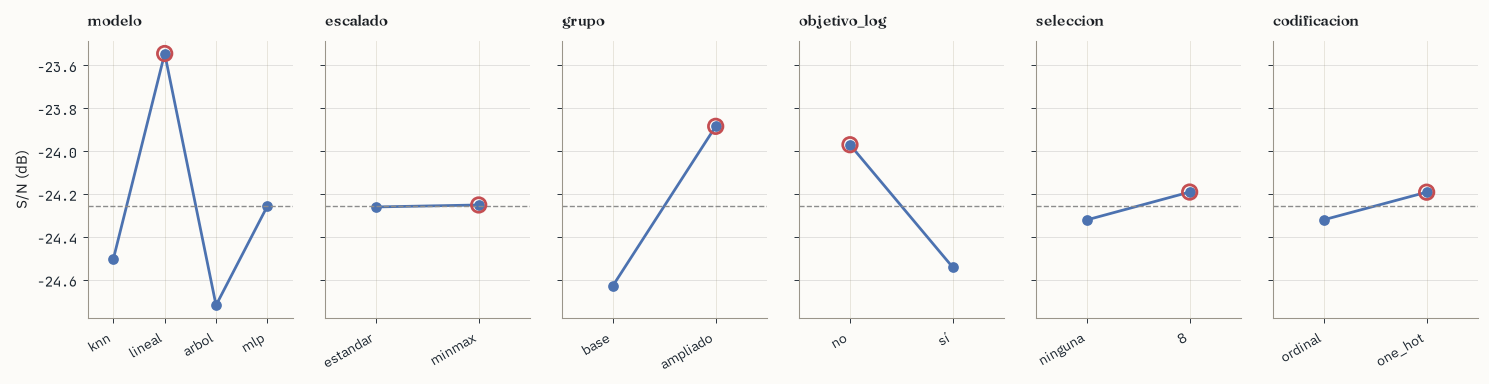

Factor,Mejor nivel,S/N mejor,Peor nivel,S/N peor,Delta,Rango
modelo,lineal,-23.55,arbol,-24.72,1.17,1
grupo,ampliado,-23.89,base,-24.63,0.74,2
objetivo_log,no,-23.97,sí,-24.54,0.57,3
seleccion,8,-24.19,ninguna,-24.32,0.13,4
codificacion,one_hot,-24.19,ordinal,-24.32,0.13,5
escalado,minmax,-24.25,estandar,-24.26,0.01,6


In [9]:
regresion.corridas_l16(c).mostrar()

### Corrida de confirmación y factorial completo

El óptimo predicho supone efectos que se suman sin interactuar: se ejecuta y se compara la S/N
observada con la predicha, con una tolerancia de dos veces el error residual del modelo aditivo.
Después, si el tiempo estimado (el del L16 por 128 / 16) no pasa de un minuto, se ejecuta el
factorial completo para comprobar el atajo de Taguchi.

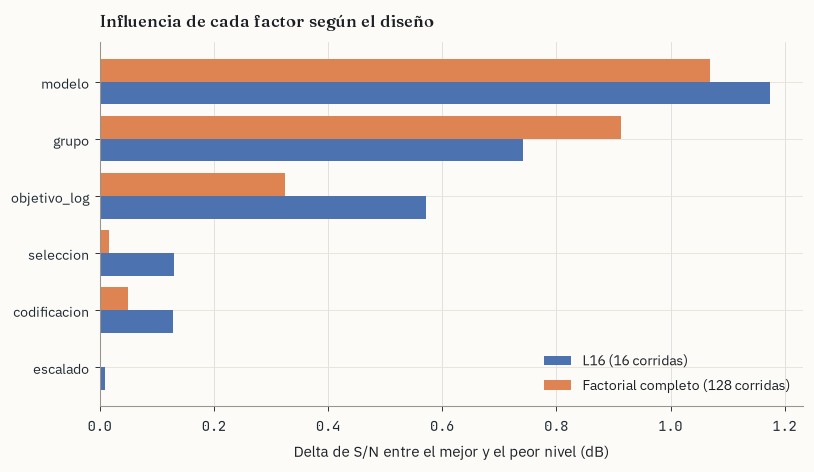

In [10]:
regresion.confirmacion(c).mostrar()

## 4. Nivel 3: afinamiento de hiperparámetros

Pasa la configuración de mayor S/N observada (la confirmación o la mejor del L16) y, para no
apostar a una sola familia, la segunda mejor familia de modelos con los demás factores iguales. Las
rejillas se recorren con `GridSearchCV` sobre los mismos bloques temporales.

In [11]:
regresion.afinamiento(c).mostrar()

### Evaluación única en validación

La regla se fija antes de mirar: gana el menor RMSE de validación y, si la diferencia es menor que
el 1 %, el modelo más sencillo (lineal, árbol, KNN, perceptrón).

In [12]:
regresion.evaluacion_validacion(c).mostrar()

Predictor,MAE,RMSE,R2,Habilidad,RMSE inf.,RMSE sup.,Habilidad inf.,Habilidad sup.
Regresión lineal,11.030,14.591,0.367,0.249,12.229,17.211,0.154,0.343
Perceptrón multicapa,11.730,15.513,0.285,0.201,13.061,18.458,0.102,0.292
base_dia_anterior,20.688,25.768,-0.973,-0.327,—,—,—,—
base_media_5,15.355,19.423,-0.121,0.000,—,—,—,—
Dummy (media),18.436,24.121,-0.729,-0.242,—,—,—,—


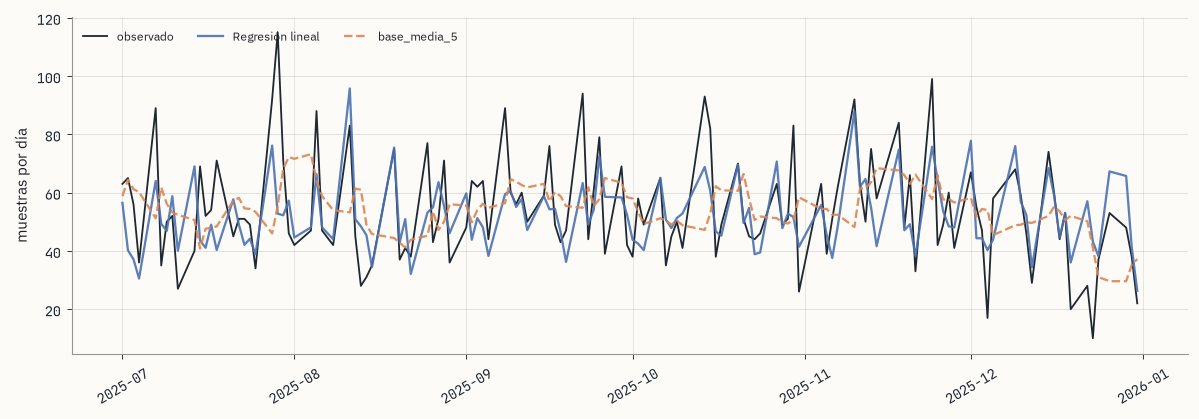

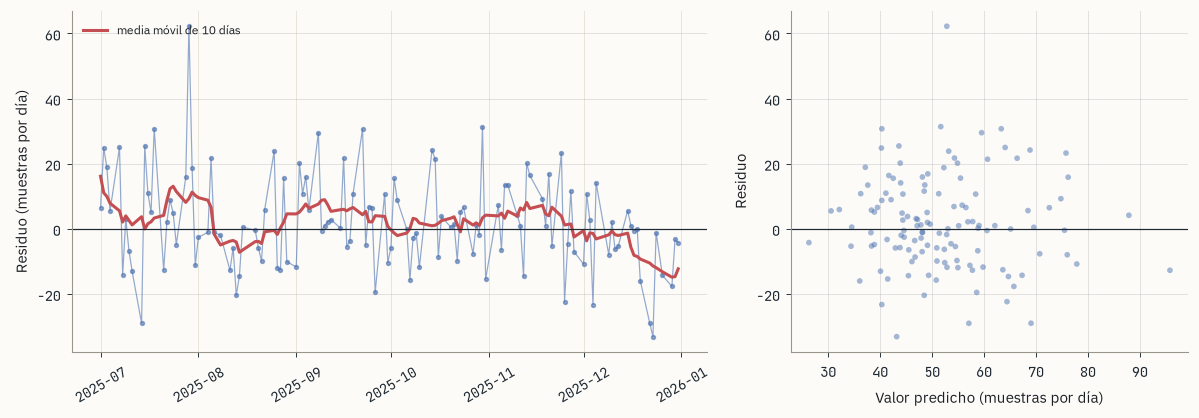

In [13]:
regresion.diagnostico(c).mostrar()

## 5. Congelamiento del modelo

Hiperparámetros y configuración quedan fijos; el modelo se reajusta con entrenamiento y validación,
porque los días recientes describen mejor el nivel actual de la serie. La etapa 07 lo evaluará una
sola vez en la prueba.

In [14]:
regresion.congelar(c).mostrar()

## 6. Qué significa en la operación

El error se traduce a muestras por día y a la frecuencia con que la predicción se aleja más de una
tolerancia práctica, fijada en el 20 % de la carga diaria media de validación.

In [15]:
regresion.operacion(c).mostrar()

In [16]:
regresion.terminar(c)

← Anterior: [03 · Cribado de análisis](03_cribado_analisis.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [05 · Clasificación y Bayes](05_clasificacion_bayes.ipynb) →